<a href="https://colab.research.google.com/github/pavisriram18-debug/deep-learning/blob/main/DL_ASSIGNMENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (9357, 15)
Number of CO records: 9357
Input shape: (9333, 24, 1)
Output shape: (9333, 1)
Training samples: 7466
Testing samples : 1867
Epoch 1/5
234/234 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0112
Epoch 2/5
234/234 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0057
Epoch 3/5
234/234 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0039
Epoch 4/5
234/234 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0034
Epoch 5/5
234/234 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0032

========== FINAL RESULT ==========
Actual CO    : [2.2 1.5 1.2 1.5 1.4]
Predicted CO : [2.5565767 2.5027626 1.7199161 1.6071659 1.9106116]
MAE          : 0.4982


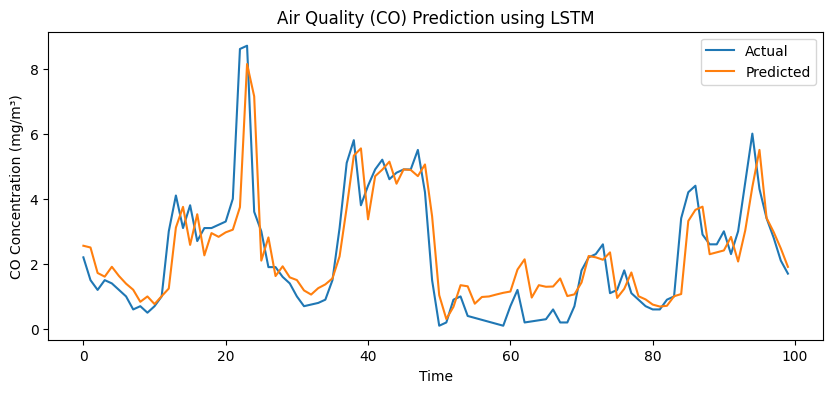

In [ ]:
# AIR QUALITY (CO) PREDICTION USING LSTM

# 1. Install and import libraries
!pip -q install ucimlrepo

import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

# 2. Load the UCI Air Quality dataset
air_quality = fetch_ucirepo(id=360)
data = air_quality.data.features

print("Dataset shape:", data.shape)

# 3. Select CO concentration and handle missing values
co = data['CO(GT)'].replace(-200, np.nan)
co = co.interpolate().dropna().values

print("Number of CO records:", len(co))

# 4. Normalize the data
scaler = MinMaxScaler()
co = scaler.fit_transform(co.reshape(-1, 1))

# 5. Create sequences
# Previous 24 hours -> predict next hour
X, y = [], []

for i in range(24, len(co)):
    X.append(co[i-24:i])
    y.append(co[i])

X = np.array(X)
y = np.array(y)

print("Input shape:", X.shape)
print("Output shape:", y.shape)

# 6. Split into training and testing data
split = int(0.8 * len(X))

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

# 7. Build the LSTM model
model = Sequential([
    Input(shape=(24, 1)),
    LSTM(32),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

# 8. Train the model
model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    verbose=1
)

# 9. Predict on test data
pred = model.predict(X_test, verbose=0)

# 10. Convert values back to original CO scale
actual = scaler.inverse_transform(y_test)
pred = scaler.inverse_transform(pred)

# 11. Calculate MAE
mae = mean_absolute_error(actual, pred)

print("\n========== FINAL RESULT ==========")
print("Actual CO    :", actual[:5].flatten())
print("Predicted CO :", pred[:5].flatten())
print("MAE          :", round(mae, 4))

# 12. Plot Actual vs Predicted
plt.figure(figsize=(10, 4))

plt.plot(actual[:100], label="Actual")
plt.plot(pred[:100], label="Predicted")

plt.title("Air Quality (CO) Prediction using LSTM")
plt.xlabel("Time")
plt.ylabel("CO Concentration (mg/m³)")
plt.legend()
plt.show()